
# THE HIDDEN RISK
### Not Every Strike Is Equal

**Exploratory Data Analysis of FAA Wildlife Strikes (2020–2025)**

## 1. Project Overview

### Dataset
- **Source:** Federal Aviation Administration (FAA)
- **Dataset:** National Wildlife Strike Database
- **Period:** 2020–2025
- **Records:** 110,940 reported wildlife strikes
- **Source Link:** https://wildlife.faa.gov/

### Why This Dataset?

Wildlife strikes can damage aircraft and affect aviation safety. This dataset provides information about reported collisions, animal characteristics, flight conditions, and aircraft damage.

It was selected to investigate whether the frequency of reported strikes reflects the likelihood of recorded aircraft damage among reported strikes.

### Problem Statement

The number of reported wildlife strikes alone may not accurately represent the damage associated with different animals and flight conditions.

This project examines the factors associated with reported aircraft damage and investigates why frequently reported strikes are not necessarily the most damaging.

### Main Research Question

**What factors are associated with aircraft damage in reported wildlife strikes, and why can strike frequency alone be misleading?**

### Research Objectives

1. Examine wildlife strike patterns from 2020 to 2025.
2. Investigate the relationship between animal size and aircraft damage.
3. Compare strike frequency and damage rates across animal species.
4. Explore how flight phase and animal size relate to damage.
5. Identify meaningful insights and limitations to support aviation safety analysis.


In [1]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Load the Dataset
df = pd.read_csv("/content/drive/MyDrive/FAA_2020_2025.csv",low_memory=False)

In [3]:
df.head()

,INDEX_NR,INCIDENT_DATE,INCIDENT_MONTH,INCIDENT_YEAR,TIME,TIME_OF_DAY,AIRPORT_ID,AIRPORT,LATITUDE,LONGITUDE,...,NR_INJURIES,NR_FATALITIES,COMMENTS,IMAGE,REPORTED_NAME,REPORTED_TITLE,SOURCE,PERSON,LUPDATE,TRANSFER
0,973031,2020-01-01,1,2020,19:30,Night,KSFB,ORLANDO SANFORD INTL ARPT,28.77764,-81.23749,...,NaN,NaN,*** Strike Report: 2020-01-01-212951-R0( Repor...,False,REDACTED,REDACTED,FAA Form 5200-7-E,Pilot,2020-04-20,0
1,973209,2020-02-05,2,2020,09:50,NaN,KCOU,COLUMBIA REGIONAL,38.81809,-92.21963,...,NaN,NaN,NaN,False,REDACTED,REDACTED,FAA Form 5200-7-E,Airport Operations,2020-04-21,0
2,973468,2020-01-18,1,2020,17:58,Day,KCRG,CRAIG MUNICIPAL ARPT,30.33633,-81.51444,...,NaN,NaN,NaN,False,REDACTED,REDACTED,FAA Form 5200-7-E,Pilot,2020-04-23,0
3,973652,2020-01-05,1,2020,19:40,Night,KOAK,METRO OAKLAND INTL,37.72129,-122.22072,...,NaN,NaN,*** Strike Report: 2020-01-05-233300-R0( Repor...,True,REDACTED,REDACTED,FAA Form 5200-7-E,Airport Operations,2020-04-27,0
4,973735,2020-01-09,1,2020,15:30,Day,KRDU,RALEIGH-DURHAM INTL,35.87764,-78.78747,...,NaN,NaN,*** Strike Report: 2020-01-10-074542-R1( Repor...,False,REDACTED,REDACTED,FAA Form 5200-7-E,Airport Operations,2020-04-27,0


In [4]:
df.shape # 110940 rows & 102 columns

(110940, 102)

In [5]:
df.info() # as the dataset columns are alot it didn't display each column name

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110940 entries, 0 to 110939
Columns: 102 entries, INDEX_NR to TRANSFER
dtypes: bool(1), float64(19), int64(41), object(41)
memory usage: 85.6+ MB


In [6]:
# Columns Selection : selected columns that are relevant to the research questions
selected_cols = [
    "INDEX_NR",
    "INCIDENT_DATE",
    "INCIDENT_YEAR",
    "INCIDENT_MONTH",
    "SPECIES",
    "SIZE",
    "PHASE_OF_FLIGHT",
    "INDICATED_DAMAGE",
    "DAMAGE_LEVEL",
    "HEIGHT",
    "NUM_STRUCK"]
df_selected = df[selected_cols].copy()
df_selected.shape

(110940, 11)

In [7]:
df_selected.info() # some columns may need data type conversion

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110940 entries, 0 to 110939
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   INDEX_NR          110940 non-null  int64  
 1   INCIDENT_DATE     110940 non-null  object 
 2   INCIDENT_YEAR     110940 non-null  int64  
 3   INCIDENT_MONTH    110940 non-null  int64  
 4   SPECIES           110940 non-null  object 
 5   SIZE              88724 non-null   object 
 6   PHASE_OF_FLIGHT   60536 non-null   object 
 7   INDICATED_DAMAGE  110940 non-null  int64  
 8   DAMAGE_LEVEL      66159 non-null   object 
 9   HEIGHT            45217 non-null   float64
 10  NUM_STRUCK        110693 non-null  object 
dtypes: float64(1), int64(4), object(6)
memory usage: 9.3+ MB


In [8]:
df_selected.describe()

,INDEX_NR,INCIDENT_YEAR,INCIDENT_MONTH,INDICATED_DAMAGE,HEIGHT
count,1.109400e+05,110940.000000,110940.00000,110940.000000,45217.000000
mean,1.476651e+06,2022.890896,7.27523,0.038886,919.897273
std,2.232240e+05,1.653471,2.69947,0.193324,1868.659804
min,9.730310e+05,2020.000000,1.00000,0.000000,0.000000
25%,1.339673e+06,2022.000000,5.00000,0.000000,0.000000
50%,1.524942e+06,2023.000000,8.00000,0.000000,40.000000
75%,1.631332e+06,2024.000000,9.00000,0.000000,1000.000000
max,1.921433e+06,2025.000000,12.00000,1.000000,32000.000000


In [9]:
# Missing values percentage to decide what to do
(df_selected.isnull().sum() / len(df_selected) * 100).round(2)

,0
INDEX_NR,0.00
INCIDENT_DATE,0.00
INCIDENT_YEAR,0.00
INCIDENT_MONTH,0.00
SPECIES,0.00
SIZE,20.03
PHASE_OF_FLIGHT,45.43
INDICATED_DAMAGE,0.00
DAMAGE_LEVEL,40.37
HEIGHT,59.24


In [10]:
# Check duplicates
df_selected.duplicated().sum()

np.int64(0)

In [11]:
'''
after exploring missing values and duplicates , it shows that we have above 5% missing values
so we can't easly just drop or fill because it might influence on the analysis later so this the decisions:
- filled missing categorical values with "Not recorded" to preserve the reports without assuming the missing
information was known.
- dropped "HEIGHT" due to its high missing percentage (59.24%) and its not an essential column.
- there are no duplicates so no rows were removed.
'''

df_clean = df_selected.copy()

df_clean["SIZE"] = df_clean["SIZE"].fillna("Not recorded")
df_clean["PHASE_OF_FLIGHT"] = df_clean["PHASE_OF_FLIGHT"].fillna("Not recorded")
df_clean["DAMAGE_LEVEL"] = df_clean["DAMAGE_LEVEL"].fillna("Not recorded")
df_clean["NUM_STRUCK"] = df_clean["NUM_STRUCK"].fillna("Not recorded")

df_clean = df_clean.drop(columns=["HEIGHT"])

In [12]:
# check after cleaning
df_clean.isnull().sum()

,0
INDEX_NR,0
INCIDENT_DATE,0
INCIDENT_YEAR,0
INCIDENT_MONTH,0
SPECIES,0
SIZE,0
PHASE_OF_FLIGHT,0
INDICATED_DAMAGE,0
DAMAGE_LEVEL,0
NUM_STRUCK,0


In [13]:
df_clean.shape

(110940, 10)

In [14]:
print(df_clean["SIZE"].value_counts())
print(df_clean["NUM_STRUCK"].value_counts())
print(df_clean["DAMAGE_LEVEL"].value_counts() )

SIZE
Small           73307
Not recorded    22216
Medium          10293
Large            5124
Name: count, dtype: int64
NUM_STRUCK
1                101504
2-10               8878
11-100              304
Not recorded        247
More than 100         7
Name: count, dtype: int64
DAMAGE_LEVEL
N               61846
Not recorded    44781
M?               3512
M                 530
S                 262
D                   9
Name: count, dtype: int64


In [15]:
#handling data types: convert "INCIDENT_DATE" to a datatime
df_clean["INCIDENT_DATE"] = pd.to_datetime(df_clean["INCIDENT_DATE"])
df_clean["INCIDENT_DATE"].dtype

dtype('<M8[ns]')

In [16]:
# Check if the years match the incident dates
(df_clean["INCIDENT_DATE"].dt.year != df_clean["INCIDENT_YEAR"]).sum()

np.int64(0)

In [17]:
'''
"NUM_STRUCK" column contains ranges representing the number of animals involved in each strike.to support a clearer comparison,
"STRIKE_GROUP" was created to classify strikes as Single, Multiple, or Unknown.
'''
df_clean["STRIKE_GROUP"] = df_clean["NUM_STRUCK"].map({
    "1": "Single",
    "2-10": "Multiple",
    "11-100": "Multiple",
    "More than 100": "Multiple",
    "Not recorded": "Unknown"})
df_clean["STRIKE_GROUP"].value_counts()

,count
STRIKE_GROUP,
Single,101504
Multiple,9189
Unknown,247


In [18]:
#check null
df_clean["STRIKE_GROUP"].isnull().sum()

np.int64(0)

In [19]:
# save cleaned data
df_clean.to_csv("/content/FAA_Cleaned.csv", index=False)

## Univariate EDA

1.How often do wildlife strikes cause aircraft damage?

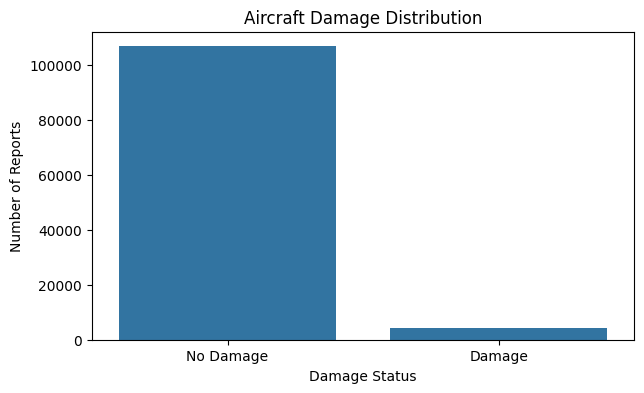

In [20]:
#count number of reports using countplot
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="INDICATED_DAMAGE")
plt.title("Aircraft Damage Distribution")
plt.xlabel("Damage Status")
plt.ylabel("Number of Reports")
plt.xticks([0, 1], ["No Damage", "Damage"])
plt.show()

Observation:
we can observe that most wildlife strikes didn't result a damage , only a small number of reports involved damage.So , what factors that associated with damging wildlife strikes?

2.What is the most frequently reported animal size in wildlife strikes

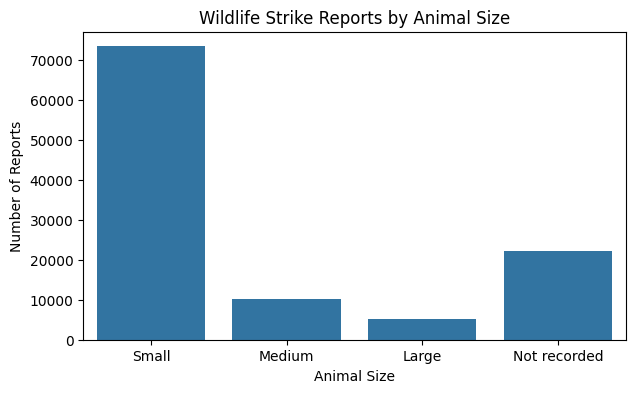

In [21]:
# animal size distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean,x="SIZE",order=["Small", "Medium", "Large", "Not recorded"])
plt.title("Wildlife Strike Reports by Animal Size")
plt.xlabel("Animal Size")
plt.ylabel("Number of Reports")
plt.show()

Observation: small animals are the most frequently reported while large animals are reported less frequently.However, some reports have no recorded animal size.


3.How are monthly wildlife strike counts distributed across 2020-2025?

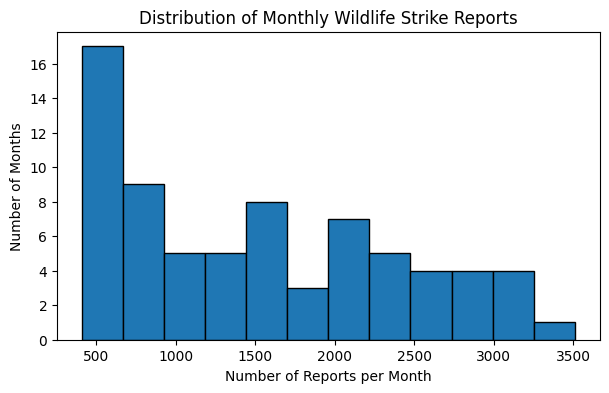

In [22]:
# counts reports for each month in each year
monthly_counts = df_clean.groupby(["INCIDENT_YEAR", "INCIDENT_MONTH"]).size()
# Histogram
plt.figure(figsize=(7, 4))
plt.hist(monthly_counts,bins=12,edgecolor="black")
plt.title("Distribution of Monthly Wildlife Strike Reports")
plt.xlabel("Number of Reports per Month")
plt.ylabel("Number of Months")
plt.show()

Observation: the plot show a wide variation, alot of months have low report counts while fewer months have much higher counts.

4.does the distribution of monthly wildlife strike reports vary across years?

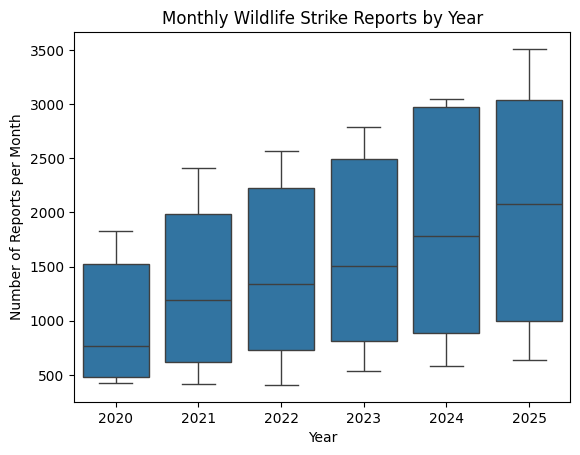

In [23]:
monthly_df = df_clean.groupby(["INCIDENT_YEAR", "INCIDENT_MONTH"],as_index=False).size()
sns.boxplot(data=monthly_df, x="INCIDENT_YEAR", y="size")
plt.title("Monthly Wildlife Strike Reports by Year")
plt.xlabel("Year")
plt.ylabel("Number of Reports per Month")
plt.show()


Observation: The median monthly reports increased from 2020 to 2025.

Interpretation: Reported strikes have increased over time. However, as shown earlier in the damage distribution, not all reported strikes involve aircraft damage. Therefore, strike frequency alone does not fully describe damage patterns.



## Bivariate Analysis

1.Does the most frequently reported animal size also have the highest damage rate?

In [24]:
# Animal size vs Aircraft damage
size_damage = df_clean.groupby("SIZE")["INDICATED_DAMAGE"].mean() * 100
print(size_damage.round(2))

SIZE
Large           24.36
Medium          11.16
Not recorded     3.72
Small            1.49
Name: INDICATED_DAMAGE, dtype: float64


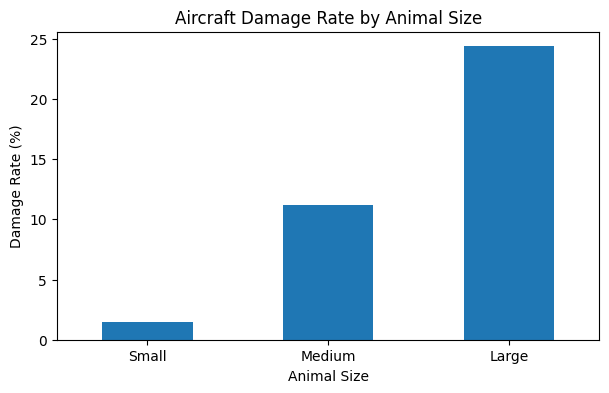

In [25]:
plt.figure(figsize=(7, 4))
size_damage[["Small", "Medium", "Large"]].plot(kind="bar") # "not recorded" was excluded because the animal size is unknown
plt.title("Aircraft Damage Rate by Animal Size")
plt.xlabel("Animal Size")
plt.ylabel("Damage Rate (%)")
plt.xticks(rotation=0)
plt.show()


Observation: large animals have the highest reported damage rate compared with medium and small animals.

Insight: Although small animals appear most frequently in strike reports, large animals are associated with a much higher damage rate.

2.Are the most frequently reported animals also associated with the highest damage rates?

In [26]:
df_clean["SPECIES"].nunique()

785

In [27]:
# explore the 20 most frequently reported wildlife categories
top_species = df_clean["SPECIES"].value_counts().head(20)
print(top_species)

SPECIES
Unknown bird                 22131
Unknown bird - small         12649
Mourning dove                 6693
Barn swallow                  4775
Killdeer                      4359
Horned lark                   4309
American kestrel              3755
Unknown bird - medium         2566
Eastern meadowlark            2298
European starling             1817
Cliff swallow                 1504
Red-tailed hawk               1358
Western meadowlark            1168
American robin                1148
Rock pigeon                   1119
Brazilian free-tailed bat     1102
Chimney swift                  962
Savannah sparrow               852
American barn owl              761
Microbats                      713
Name: count, dtype: int64


In [28]:
# Exclude unknown species
known_species = df_clean[df_clean["SPECIES"].str.contains("Unknown", case=False) == False]
# Top 20 most frequent species
top_species = known_species["SPECIES"].value_counts().head(20)
print(top_species)

SPECIES
Mourning dove                6693
Barn swallow                 4775
Killdeer                     4359
Horned lark                  4309
American kestrel             3755
Eastern meadowlark           2298
European starling            1817
Cliff swallow                1504
Red-tailed hawk              1358
Western meadowlark           1168
American robin               1148
Rock pigeon                  1119
Brazilian free-tailed bat    1102
Chimney swift                 962
Savannah sparrow              852
American barn owl             761
Microbats                     713
Perching birds (y)            670
Sparrows                      661
Gulls                         655
Name: count, dtype: int64


Observation: it was observed that Mourning dove is the most frequently reported but is it the most one that caused a damage?

3.Which reported animal categories have the highest aircraft damage rates

In [29]:
species_damage = known_species.groupby("SPECIES")["INDICATED_DAMAGE"].agg(["count", "mean"])
species_damage = species_damage[species_damage["count"] >= 100] # the ranking excludes categories with fewer than 100 reports
species_damage["Damage Rate"] = (species_damage["mean"] * 100).round(2)
species_damage.sort_values("Damage Rate", ascending=False).head(10)

,count,mean,Damage Rate
SPECIES,,,
White-tailed deer,202,0.737624,73.76
Black vulture,184,0.641304,64.13
Turkey vulture,431,0.422274,42.23
Canada goose,427,0.353630,35.36
Bald eagle,264,0.325758,32.58
Osprey,253,0.221344,22.13
White-headed gull complex,238,0.197479,19.75
Hawks,236,0.186441,18.64
Mallard,394,0.180203,18.02


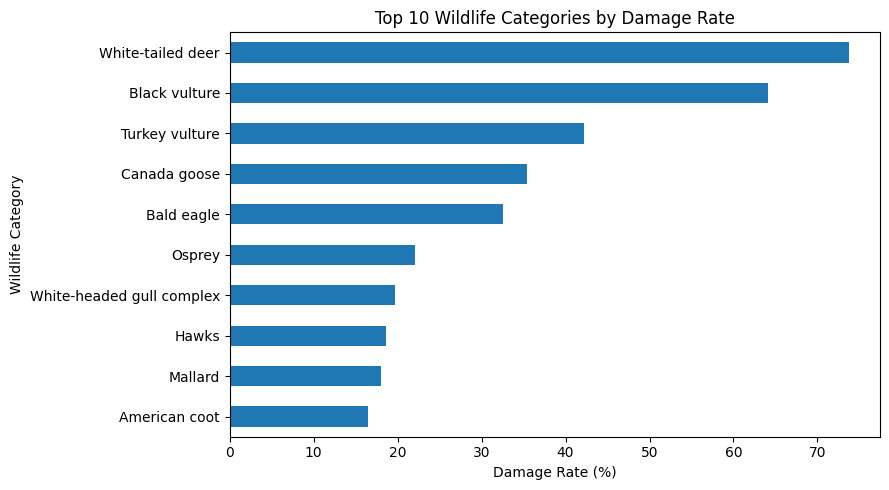

In [30]:
top_damage = species_damage.sort_values("Damage Rate", ascending=False).head(10)
plt.figure(figsize=(9, 5))
top_damage["Damage Rate"].sort_values().plot(kind="barh")
plt.title("Top 10 Wildlife Categories by Damage Rate")
plt.xlabel("Damage Rate (%)")
plt.ylabel("Wildlife Category")
plt.tight_layout()
plt.show()

In [31]:
# to clearly show the comparison between most frequently reported animal and the highest damage rate animal
species_damage.loc[["Mourning dove", "White-tailed deer"],["count", "Damage Rate"]]

,count,Damage Rate
SPECIES,,
Mourning dove,6693,1.30
White-tailed deer,202,73.76


Observation: White-tailed deer had the highest recorded damage rate with at least 100 reports, followed by black vultures.

Insight: The most frequently reported wildlife categories are not necessarily those with the highest damage rates.


4.Did the increase in reported wildlife strikes also lead to an increase in the percentage of damaging strikes?

In [32]:
# Annual strike trends vs Damage rate
# Number of reported strikes each year
yearly_count = df_clean.groupby("INCIDENT_YEAR")["INDICATED_DAMAGE"].count()
# Percentage of damaging reports each year
yearly_damage = df_clean.groupby("INCIDENT_YEAR")["INDICATED_DAMAGE"].mean() * 100
print("Annual Strike Count:", yearly_count)
print("\nAnnual Damage Rate (%):",yearly_damage.round(2))

Annual Strike Count: INCIDENT_YEAR
2020    11627
2021    15641
2022    17223
2023    19623
2024    22370
2025    24456
Name: INDICATED_DAMAGE, dtype: int64

Annual Damage Rate (%): INCIDENT_YEAR
2020    4.25
2021    4.26
2022    4.08
2023    3.67
2024    3.68
2025    3.70
Name: INDICATED_DAMAGE, dtype: float64


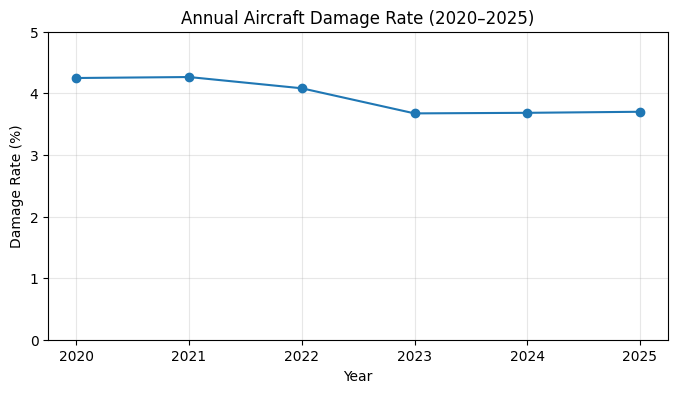

In [33]:
plt.figure(figsize=(8, 4))
plt.plot(yearly_damage.index, yearly_damage.values, marker="o")
plt.title("Annual Aircraft Damage Rate (2020–2025)")
plt.xlabel("Year")
plt.ylabel("Damage Rate (%)")
plt.ylim(0, 5)
plt.grid(alpha=0.3)
plt.show()

Observation: Reported wildlife strikes increased every year from 2020 to 2025, while the damage rate decreased overall from 4.25% to 3.70%, with minor fluctuations.

Insight: An increase in reported strike frequency doesn't necessarily indicate a higher proportion of damaging strikes.


5.Are multiple-animal strikes associated with higher recorded damage rates than single-animal strikes?

In [34]:
strike_group_damage = df_clean.groupby("STRIKE_GROUP")["INDICATED_DAMAGE"].agg(["count", "mean"])
strike_group_damage["Damage Rate"] = (strike_group_damage["mean"] * 100).round(2)
print(strike_group_damage)

               count      mean  Damage Rate
STRIKE_GROUP                               
Multiple        9189  0.072043         7.20
Single        101504  0.035841         3.58
Unknown          247  0.056680         5.67


Observation: Multiple-animal strikes had a recorded damage rate of 7.20% compared with 3.58% for single-animal strikes.

Insight: Reports involving multiple animals were associated with approximately twice the damage rate of reports involving a single animal.


## Multivariate Analysis

1.Does the relationship between animal size and aircraft damage vary across flight phases?

In [35]:
df_clean["PHASE_OF_FLIGHT"].value_counts()

,count
PHASE_OF_FLIGHT,
Not recorded,50404
Approach,26141
Landing Roll,11370
Take-off Run,9224
Climb,7068
Departure,2280
En Route,2036
Descent,944
Local,623


In [36]:
# Select flight phases with enough reports
phases = ["Approach", "Landing Roll", "Take-off Run","Climb", "Departure", "En Route"]
# Keep selected phases and recorded animal sizes
df_phase = df_clean[(df_clean["PHASE_OF_FLIGHT"].isin(phases))&(df_clean["SIZE"].isin(["Small", "Medium", "Large"]))]
# Compare damage within each flight phase and animal size
phase_size_damage = df_phase.groupby(["PHASE_OF_FLIGHT", "SIZE"])["INDICATED_DAMAGE"].agg(["count", "mean"])
print(phase_size_damage.round(2))

                        count  mean
PHASE_OF_FLIGHT SIZE               
Approach        Large    1228  0.40
                Medium   2719  0.17
                Small   13105  0.03
Climb           Large     486  0.53
                Medium    892  0.25
                Small    3138  0.05
Departure       Large      40  0.32
                Medium     82  0.18
                Small     724  0.03
En Route        Large     149  0.74
                Medium    320  0.39
                Small    1029  0.07
Landing Roll    Large     672  0.28
                Medium    992  0.07
                Small    7913  0.01
Take-off Run    Large     523  0.23
                Medium    993  0.12
                Small    6110  0.02


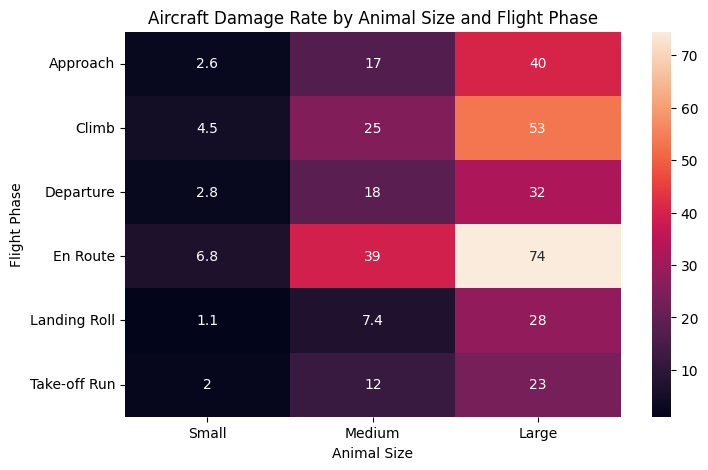

In [37]:
# Convert grouped results into a table
heatmap_data = phase_size_damage["mean"].unstack() * 100
heatmap_data = heatmap_data[["Small", "Medium", "Large"]]
plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_data,annot=True)
plt.title("Aircraft Damage Rate by Animal Size and Flight Phase")
plt.xlabel("Animal Size")
plt.ylabel("Flight Phase")
plt.show()

Observation: Large animals had the highest recorded damage rate across all six selected flight phases. Damage rates also varied between flight phases within the same animal size category.

Insight: Aircraft damage is associated with both animal size and flight phase.

Note: Approximately 45% of reports had no recorded flight phase, and 20% had no recorded animal size. These reports were excluded from this comparison.

## Key Findings & Conclusion

### Key Findings

**1. Animal size matters**

Small animals were involved in the most reported strikes, but large animals had a much higher recorded damage rate (24.36%) compared with small animals (1.49%).

**2. Frequency doesn't equal Damage rate**

Mourning doves had 6,693 reported strikes with a damage rate of 1.30% while white-tailed deer had only 202 reports but a damage rate of 73.76%.This shows why strike frequency alone can be misleading.

**3. Reported Strikes Increased, While Damage Rates Decreased Overall**

Reported wildlife strikes increased from 11,627 in 2020 to 24,456 in 2025.However,the percentage of reports involving aircraft damage decreased overall from 4.25% to 3.70%.

**4. Flight conditions and Strike characteristics matter**

Damage rates varied across flight phases even within the same animal size category. In addition, multiple-animal strikes had approximately twice the recorded damage rate of single-animal strikes (7.20% vs. 3.58%).


### Limitations

- The analysis is based on reported wildlife strikes, not all flights.
- Approximately 45% of reports had no recorded flight phase, and 20% had no recorded animal size.
- Species damage rankings included only wildlife categories with at least 100 reports.
- The findings show associations, not causation.

### Outliers and Unusual Cases

The monthly boxplots didn't show a clear outliers in the displayed distributions.Some strike categories had very few reports, such as strikes involving more than 100 animals (7 reports), so their damage rates should be interpreted cautiously.

### Recommendations

Aviation safety analysis should consider both strike frequency and recorded damage rates rather than relying on report counts alone.

Future analysis could include flight activity data, more complete flight-phase information, and additional aircraft-related factors to better understand damage patterns.


### Conclusion

The analysis shows that wildlife strike frequency alone doesn't
fully describe aircraft damage patterns.Animal size, flight phase, and the number of animals involved are all associated with differences in recorded damage rates.
